# Apex Track: a race circuit in PyBullet

This notebook builds a small race circuit in PyBullet and studies it with three cameras.

| Brief requirement | Where in this notebook |
|---|---|
| Four or more URDF models with distinct roles | Section 2 writes eight scenery models, each with its own role |
| One two-wheel robot URDF | Section 2, `racer.urdf` (two driven wheels, one caster) |
| Eight or more objects plus the robot in a meaningful scene | Section 3 places 38 scenery bodies and the racer |
| Roles stored in code, objects identified by code | Section 4, the `REGISTRY` dict and its helpers |
| DIRECT mode | Section 1, `p.connect(p.DIRECT)` |
| Three camera views, static objects fixed, robot moved | Sections 5 and 6 |
| All objects and the robot visible across views | Section 7, segmentation mask asserts |
| Interaction or query | Section 8, three queries |
| Matplotlib display | Sections 6 and 8 |
| Reflection with failed attempts | Section 9 |

Everything the notebook needs is written by its own cells. Use "Restart and Run All".

## 1. Setup

PyBullet runs in DIRECT mode, with no window. All images come from the tiny software renderer.

In [1]:
import math
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pybullet as p

URDF_DIR = Path("urdf")
FIG_DIR = Path("figures")
URDF_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

client = p.connect(p.DIRECT)
p.resetSimulation()
p.setGravity(0, 0, -9.81)
TIME_STEP = 1.0 / 240.0
p.setTimeStep(TIME_STEP)
print("PyBullet connected in DIRECT mode, client id", client)

PyBullet connected in DIRECT mode, client id 0


pybullet build time: Jan 29 2025 23:17:20


## 2. URDF models

The circuit is a stadium oval. Two straights run along y = -3 and y = +3 from x = -4 to x = +4.
Two half circles of radius 3 join them, centred on (-4, 0) and (+4, 0). The track is 1.6 m wide.
The car runs anticlockwise: front straight, turn one on the right, back straight, turn two on the left.

A small helper writes URDF text. Each model below is one function that returns a URDF string.

In [2]:
TRACK_HALF_STRAIGHT = 4.0   # straights run from x = -4 to x = +4
TRACK_RADIUS = 3.0          # radius of the centre line in the turns
TRACK_WIDTH = 1.6


def rgba(c):
    return " ".join(f"{v:.3f}" for v in c)


def material(name, color):
    return f'<material name="{name}"><color rgba="{rgba(color)}"/></material>'


def box(size):
    return f'<box size="{size[0]} {size[1]} {size[2]}"/>'


def cylinder(radius, length):
    return f'<cylinder radius="{radius}" length="{length}"/>'


def sphere(radius):
    return f'<sphere radius="{radius}"/>'


def visual(geom, xyz=(0, 0, 0), rpy=(0, 0, 0), mat=None):
    m = mat or ""
    return (f'<visual><origin xyz="{xyz[0]} {xyz[1]} {xyz[2]}" rpy="{rpy[0]} {rpy[1]} {rpy[2]}"/>'
            f'<geometry>{geom}</geometry>{m}</visual>')


def collision(geom, xyz=(0, 0, 0), rpy=(0, 0, 0)):
    return (f'<collision><origin xyz="{xyz[0]} {xyz[1]} {xyz[2]}" rpy="{rpy[0]} {rpy[1]} {rpy[2]}"/>'
            f'<geometry>{geom}</geometry></collision>')


def inertial(mass, ixx=0.001, iyy=0.001, izz=0.001, xyz=(0, 0, 0)):
    return (f'<inertial><origin xyz="{xyz[0]} {xyz[1]} {xyz[2]}"/><mass value="{mass}"/>'
            f'<inertia ixx="{ixx}" ixy="0" ixz="0" iyy="{iyy}" iyz="0" izz="{izz}"/></inertial>')


def shape(geom, xyz=(0, 0, 0), rpy=(0, 0, 0), mat=None, solid=True):
    """One visual, plus a matching collision when solid is True."""
    out = visual(geom, xyz, rpy, mat)
    if solid:
        out += collision(geom, xyz, rpy)
    return out


def robot_urdf(name, links_xml):
    return f'<?xml version="1.0"?>\n<robot name="{name}">\n{links_xml}\n</robot>\n'


def write_urdf(filename, text):
    # One tag per line. PyBullet's URDF parser failed on the long single-line track file.
    path = URDF_DIR / filename
    path.write_text(text.replace("><", ">\n<"))
    return str(path)

### 2.1 Scenery models (eight models, eight roles)

Scenery bodies have mass 0, so PyBullet keeps them fixed. Colours here are the defaults.
Some instances get their own colour later (for example each spectator).

In [3]:
def barrier_urdf():
    """Concrete block with a red and white top rail. Role: obstacle."""
    concrete = material("concrete", (0.75, 0.75, 0.72, 1))
    red = material("rail_red", (0.85, 0.10, 0.10, 1))
    body = shape(box((2.0, 0.25, 0.35)), xyz=(0, 0, 0.175), mat=concrete)
    rail = shape(box((2.0, 0.27, 0.08)), xyz=(0, 0, 0.39), mat=red)
    return robot_urdf("barrier", f'<link name="base">{inertial(0)}{body}{rail}</link>')


def cone_urdf():
    """Traffic cone made of three stacked cylinders. Role: obstacle."""
    orange = material("cone_orange", (1.0, 0.45, 0.0, 1))
    white = material("cone_white", (0.95, 0.95, 0.95, 1))
    base = shape(box((0.30, 0.30, 0.03)), xyz=(0, 0, 0.015), mat=orange)
    low = shape(cylinder(0.11, 0.18), xyz=(0, 0, 0.12), mat=orange)
    band = shape(cylinder(0.08, 0.08), xyz=(0, 0, 0.25), mat=white)
    top = shape(cylinder(0.05, 0.14), xyz=(0, 0, 0.36), mat=orange)
    return robot_urdf("cone", f'<link name="base">{inertial(0)}{base}{low}{band}{top}</link>')


def checkpoint_gate_urdf():
    """Two posts and a banner bar that span the track. Role: target."""
    post_mat = material("gate_post", (0.20, 0.20, 0.22, 1))
    bar_mat = material("gate_bar", (0.10, 0.55, 0.95, 1))
    half = TRACK_WIDTH / 2 + 0.25
    left = shape(box((0.12, 0.12, 1.3)), xyz=(0, half, 0.65), mat=post_mat)
    right = shape(box((0.12, 0.12, 1.3)), xyz=(0, -half, 0.65), mat=post_mat)
    bar = shape(box((0.10, 2 * half + 0.12, 0.25)), xyz=(0, 0, 1.25), mat=bar_mat)
    return robot_urdf("checkpoint_gate", f'<link name="base">{inertial(0)}{left}{right}{bar}</link>')


def finish_pad_urdf():
    """Flat chequered pad across the track. Role: target zone."""
    white = material("pad_white", (0.97, 0.97, 0.97, 1))
    black = material("pad_black", (0.05, 0.05, 0.05, 1))
    parts = shape(box((0.6, TRACK_WIDTH, 0.006)), xyz=(0, 0, 0.003), mat=white)
    n = 8
    cell = TRACK_WIDTH / n
    for row in range(2):
        for col in range(n):
            if (row + col) % 2 == 0:
                x = -0.15 + row * 0.3
                y = -TRACK_WIDTH / 2 + cell * (col + 0.5)
                parts += visual(box((0.3, cell, 0.002)), xyz=(x, y, 0.007), mat=black)
    return robot_urdf("finish_pad", f'<link name="base">{inertial(0)}{parts}</link>')


def pit_box_urdf():
    """Yellow outlined service bay with a grey floor. Role: zone."""
    floor = material("pit_floor", (0.45, 0.45, 0.48, 1))
    yellow = material("pit_yellow", (1.0, 0.85, 0.0, 1))
    w, d = 2.0, 1.2
    parts = shape(box((w, d, 0.006)), xyz=(0, 0, 0.003), mat=floor)
    parts += visual(box((w, 0.08, 0.004)), xyz=(0, d / 2 - 0.04, 0.008), mat=yellow)
    parts += visual(box((w, 0.08, 0.004)), xyz=(0, -d / 2 + 0.04, 0.008), mat=yellow)
    parts += visual(box((0.08, d, 0.004)), xyz=(w / 2 - 0.04, 0, 0.008), mat=yellow)
    parts += visual(box((0.08, d, 0.004)), xyz=(-w / 2 + 0.04, 0, 0.008), mat=yellow)
    return robot_urdf("pit_box", f'<link name="base">{inertial(0)}{parts}</link>')


def grandstand_urdf():
    """Three stepped tiers and a back wall. Front faces local +y. Role: landmark."""
    tier = material("stand_tier", (0.55, 0.58, 0.62, 1))
    wall = material("stand_wall", (0.25, 0.30, 0.40, 1))
    parts = ""
    for i in range(3):
        h = 0.3 * (i + 1)
        parts += shape(box((4.0, 0.6, h)), xyz=(0, 0.6 - 0.6 * i, h / 2), mat=tier)
    parts += shape(box((4.0, 0.15, 1.6)), xyz=(0, -0.95, 0.8), mat=wall)
    return robot_urdf("grandstand", f'<link name="base">{inertial(0)}{parts}</link>')


def light_tower_urdf():
    """Tall pole with a lamp head. Role: landmark."""
    pole = material("tower_pole", (0.35, 0.35, 0.38, 1))
    lamp = material("tower_lamp", (1.0, 0.95, 0.60, 1))
    parts = shape(cylinder(0.08, 4.0), xyz=(0, 0, 2.0), mat=pole)
    parts += shape(box((0.7, 0.25, 0.35)), xyz=(0, 0, 4.1), mat=lamp)
    return robot_urdf("light_tower", f'<link name="base">{inertial(0)}{parts}</link>')


def spectator_urdf():
    """Cylinder body with a sphere head on a fixed joint. Role: audience."""
    shirt = material("shirt", (0.2, 0.4, 0.8, 1))
    skin = material("skin", (0.87, 0.72, 0.58, 1))
    body = f'<link name="body">{inertial(0)}{shape(cylinder(0.12, 0.5), xyz=(0, 0, 0.25), mat=shirt)}</link>'
    head = f'<link name="head">{inertial(0.0)}{shape(sphere(0.09), mat=skin)}</link>'
    joint = ('<joint name="neck" type="fixed"><parent link="body"/><child link="head"/>'
             '<origin xyz="0 0 0.59"/></joint>')
    return robot_urdf("spectator", body + head + joint)

### 2.2 Ground and track surface

These two are the stage, not part of the eight scenery roles. The track is one link made of
many flat boxes: two straights, 24 segments per turn, kerbs, and white grid slots.

In [4]:
def ground_urdf():
    grass = material("grass", (0.30, 0.55, 0.25, 1))
    return robot_urdf("ground", f'<link name="base">{inertial(0)}'
                      f'{shape(box((30, 24, 0.1)), xyz=(0, 0, -0.05), mat=grass)}</link>')


def track_urdf(segments_per_turn=24):
    asphalt = material("asphalt", (0.22, 0.22, 0.24, 1))
    kerb_r = material("kerb_red", (0.85, 0.12, 0.12, 1))
    kerb_w = material("kerb_white", (0.95, 0.95, 0.95, 1))
    line = material("paint", (0.95, 0.95, 0.95, 1))
    h = 0.004
    L = 2 * TRACK_HALF_STRAIGHT
    parts = ""
    for y in (-TRACK_RADIUS, TRACK_RADIUS):
        parts += shape(box((L, TRACK_WIDTH, h)), xyz=(0, y, h / 2), mat=asphalt)
    # Turns: segments overlap slightly so there is no gap between them.
    seg_len = TRACK_RADIUS * math.pi / segments_per_turn * 1.15
    for cx, a0 in ((TRACK_HALF_STRAIGHT, -math.pi / 2), (-TRACK_HALF_STRAIGHT, math.pi / 2)):
        for i in range(segments_per_turn):
            a = a0 + math.pi * (i + 0.5) / segments_per_turn
            x, y = cx + TRACK_RADIUS * math.cos(a), TRACK_RADIUS * math.sin(a)
            yaw = a + math.pi / 2
            parts += shape(box((seg_len, TRACK_WIDTH, h)), xyz=(x, y, h / 2), rpy=(0, 0, yaw), mat=asphalt)
            # Inside kerb, alternating red and white.
            r_in = TRACK_RADIUS - TRACK_WIDTH / 2 + 0.08
            kx, ky = cx + r_in * math.cos(a), r_in * math.sin(a)
            kmat = kerb_r if i % 2 == 0 else kerb_w
            parts += visual(box((seg_len * 0.9, 0.16, 0.002)), xyz=(kx, ky, h + 0.001), rpy=(0, 0, yaw), mat=kmat)
    # Start grid: two staggered slots behind the start, plus a start line.
    for gx, gy in ((-3.0, -3.3), (-3.8, -2.7)):
        parts += visual(box((0.05, 0.5, 0.002)), xyz=(gx + 0.3, gy, h + 0.001), mat=line)
    parts += visual(box((0.08, TRACK_WIDTH, 0.002)), xyz=(-2.5, -3.0, h + 0.001), mat=line)
    return robot_urdf("track", f'<link name="base">{inertial(0)}{parts}</link>')

### 2.3 The robot: racer.urdf

A two-wheel differential drive car. The chassis is the base link. Two driven wheels sit on
continuous joints. One caster ball sits at the rear on a fixed joint. The rear wing is three boxes
(two uprights and the wing plane) on its own fixed link.

In [5]:
WHEEL_RADIUS = 0.05
WHEEL_SEPARATION = 0.22   # distance between the two wheel centres


def racer_urdf():
    body = material("racer_body", (0.85, 0.05, 0.10, 1))
    dark = material("racer_dark", (0.08, 0.08, 0.08, 1))
    tyre = material("tyre", (0.05, 0.05, 0.05, 1))
    steel = material("steel", (0.7, 0.7, 0.72, 1))

    chassis = (f'<link name="chassis">{inertial(1.5, 0.004, 0.012, 0.014)}'
               f'{shape(box((0.34, 0.16, 0.05)), xyz=(0, 0, 0.0), mat=body)}'
               f'{visual(box((0.10, 0.10, 0.04)), xyz=(0.21, 0, -0.005), mat=body)}'
               f'{visual(box((0.12, 0.10, 0.03)), xyz=(0.00, 0, 0.04), mat=dark)}'
               f'</link>')

    def wheel(side, y):
        rot = (-math.pi / 2, 0, 0)
        return (f'<link name="{side}_wheel">{inertial(0.2, 0.0002, 0.0003, 0.0002)}'
                f'{visual(cylinder(WHEEL_RADIUS, 0.04), rpy=rot, mat=tyre)}'
                f'{collision(cylinder(WHEEL_RADIUS, 0.04), rpy=rot)}</link>'
                f'<joint name="{side}_wheel_joint" type="continuous">'
                f'<parent link="chassis"/><child link="{side}_wheel"/>'
                f'<origin xyz="0.07 {y} 0.0"/><axis xyz="0 1 0"/></joint>')

    caster = (f'<link name="caster">{inertial(0.05, 0.00002, 0.00002, 0.00002)}'
              f'{shape(sphere(0.025), mat=steel)}</link>'
              '<joint name="caster_joint" type="fixed"><parent link="chassis"/><child link="caster"/>'
              f'<origin xyz="-0.13 0 -0.025"/></joint>')

    wing = (f'<link name="rear_wing">{inertial(0.05)}'
            f'{visual(box((0.03, 0.02, 0.08)), xyz=(0, 0.06, 0.04), mat=dark)}'
            f'{visual(box((0.03, 0.02, 0.08)), xyz=(0, -0.06, 0.04), mat=dark)}'
            f'{shape(box((0.07, 0.20, 0.012)), xyz=(0, 0, 0.085), mat=body)}</link>'
            '<joint name="wing_joint" type="fixed"><parent link="chassis"/><child link="rear_wing"/>'
            '<origin xyz="-0.15 0 0.025"/></joint>')

    return robot_urdf("racer", chassis + wheel("left", WHEEL_SEPARATION / 2)
                      + wheel("right", -WHEEL_SEPARATION / 2) + caster + wing)

### 2.4 Write every URDF to disk

In [6]:
MODEL_BUILDERS = {
    "barrier": barrier_urdf,
    "cone": cone_urdf,
    "checkpoint_gate": checkpoint_gate_urdf,
    "finish_pad": finish_pad_urdf,
    "pit_box": pit_box_urdf,
    "grandstand": grandstand_urdf,
    "light_tower": light_tower_urdf,
    "spectator": spectator_urdf,
    "ground": ground_urdf,
    "track": track_urdf,
    "racer": racer_urdf,
}
URDF_PATHS = {name: write_urdf(f"{name}.urdf", build()) for name, build in MODEL_BUILDERS.items()}
for name, path in URDF_PATHS.items():
    print(f"{name:16s} -> {path} ({os.path.getsize(path)} bytes)")

barrier          -> urdf/barrier.urdf (815 bytes)
cone             -> urdf/cone.urdf (1491 bytes)
checkpoint_gate  -> urdf/checkpoint_gate.urdf (1136 bytes)
finish_pad       -> urdf/finish_pad.urdf (2151 bytes)
pit_box          -> urdf/pit_box.urdf (1319 bytes)
grandstand       -> urdf/grandstand.urdf (1486 bytes)
light_tower      -> urdf/light_tower.urdf (839 bytes)
spectator        -> urdf/spectator.urdf (1089 bytes)
ground           -> urdf/ground.urdf (504 bytes)
track            -> urdf/track.urdf (34307 bytes)
racer            -> urdf/racer.urdf (3836 bytes)


## 3. Build the scene

Each placement lists the model, a name, the position, the yaw, and an optional colour.
The model decides the role. `spawn` loads the URDF and records the body in the registry.

In [7]:
# Role and category for each model. Role is what the object is for. Category is the group it belongs to.
MODEL_INFO = {
    "barrier":         {"role": "obstacle",    "category": "track safety"},
    "cone":            {"role": "obstacle",    "category": "track marker"},
    "checkpoint_gate": {"role": "target",      "category": "timing"},
    "finish_pad":      {"role": "target zone", "category": "timing"},
    "pit_box":         {"role": "zone",        "category": "pit lane"},
    "grandstand":      {"role": "landmark",    "category": "venue"},
    "light_tower":     {"role": "landmark",    "category": "venue"},
    "spectator":       {"role": "audience",    "category": "crowd"},
    "ground":          {"role": "surface",     "category": "stage"},
    "track":           {"role": "surface",     "category": "stage"},
    "racer":           {"role": "robot",       "category": "robot"},
}

REGISTRY = {}


def spawn(model, name, x, y, yaw=0.0, z=0.0, color=None):
    pos = (x, y, z)
    orn = p.getQuaternionFromEuler((0, 0, yaw))
    body_id = p.loadURDF(URDF_PATHS[model], pos, orn, useFixedBase=(model != "racer"))
    if color is not None:
        for link in range(-1, p.getNumJoints(body_id)):
            if model == "spectator" and link == 0:
                continue  # keep the head skin coloured
            p.changeVisualShape(body_id, link, rgbaColor=color)
    REGISTRY[body_id] = {
        "name": name,
        "model": model,
        "role": MODEL_INFO[model]["role"],
        "category": MODEL_INFO[model]["category"],
        "position": pos,
        "yaw_deg": round(math.degrees(yaw), 1),
        "colour": color if color is not None else "model default",
        "static": model != "racer",
    }
    return body_id


def on_circle(cx, cy, r, angle_deg):
    a = math.radians(angle_deg)
    return cx + r * math.cos(a), cy + r * math.sin(a)


# Stage
spawn("ground", "ground", 0, 0)
spawn("track", "track surface", 0, 0)

# Barriers: three on the outside of each straight, three on the outside of each turn.
R_OUT = TRACK_RADIUS + TRACK_WIDTH / 2 + 0.45
for i, x in enumerate((-3.0, 0.0, 3.0)):
    spawn("barrier", f"barrier front straight {i + 1}", x, -R_OUT)
    spawn("barrier", f"barrier back straight {i + 1}", x, R_OUT)
for i, ang in enumerate((-50, 0, 50)):
    x, y = on_circle(TRACK_HALF_STRAIGHT, 0, R_OUT, ang)
    spawn("barrier", f"barrier turn one {i + 1}", x, y, yaw=math.radians(ang + 90))
for i, ang in enumerate((130, 180, 230)):
    x, y = on_circle(-TRACK_HALF_STRAIGHT, 0, R_OUT, ang)
    spawn("barrier", f"barrier turn two {i + 1}", x, y, yaw=math.radians(ang + 90))

# Cones mark the inside apex of each turn, off the racing line.
R_CONE = TRACK_RADIUS - TRACK_WIDTH / 2 - 0.3
for i, ang in enumerate((-35, 0, 35)):
    spawn("cone", f"apex cone turn one {i + 1}", *on_circle(TRACK_HALF_STRAIGHT, 0, R_CONE, ang))
for i, ang in enumerate((145, 180, 215)):
    spawn("cone", f"apex cone turn two {i + 1}", *on_circle(-TRACK_HALF_STRAIGHT, 0, R_CONE, ang))

# Checkpoint gates span the track. The gate's local x axis points along the track, so its
# yaw equals the track heading at that point.
x, y = on_circle(TRACK_HALF_STRAIGHT, 0, TRACK_RADIUS, 0)
spawn("checkpoint_gate", "checkpoint 1 (turn one)", x, y, yaw=math.radians(90))
spawn("checkpoint_gate", "checkpoint 2 (back straight)", 0.0, TRACK_RADIUS, yaw=math.radians(180))
x, y = on_circle(-TRACK_HALF_STRAIGHT, 0, TRACK_RADIUS, 225)
spawn("checkpoint_gate", "checkpoint 3 (turn two exit)", x, y, yaw=math.radians(315))

# Finish line on the front straight, pit box between the track and the stands.
FINISH_X = 1.0
spawn("finish_pad", "finish line", FINISH_X, -TRACK_RADIUS)
spawn("pit_box", "pit box", 5.5, -5.4)

# Venue: two grandstands facing the front straight, three light towers.
GRANDSTAND_Y = -7.2
spawn("grandstand", "main grandstand west", -2.5, GRANDSTAND_Y)
spawn("grandstand", "main grandstand east", 2.0, GRANDSTAND_Y)
spawn("light_tower", "light tower north west", -9.0, 5.0)
spawn("light_tower", "light tower north east", 9.0, 5.0)
spawn("light_tower", "light tower south east", 9.5, -6.0)

# Spectators stand on the grandstand tiers in shirts of different colours.
SHIRTS = [(0.90, 0.20, 0.20, 1), (0.20, 0.45, 0.90, 1), (1.00, 0.80, 0.10, 1),
          (0.20, 0.70, 0.30, 1), (0.60, 0.25, 0.75, 1)]
k = 0
for stand_x in (-2.5, 2.0):
    for j, (dx, tier) in enumerate(((-1.5, 0), (-0.5, 1), (0.5, 0), (1.5, 1), (0.0, 2))):
        tier_y = GRANDSTAND_Y + 0.6 - 0.6 * tier
        tier_top = 0.3 * (tier + 1)
        spawn("spectator", f"spectator {k + 1}", stand_x + dx, tier_y, z=tier_top,
              color=SHIRTS[k % len(SHIRTS)])
        k += 1

# The robot starts on the first grid slot, facing along the front straight (+x).
GRID_POSE = (-3.0 + 0.3 - 0.2, -3.0, 0.0)   # (x, y, yaw) just behind the start line
ROBOT_Z = WHEEL_RADIUS + 0.004
robot = spawn("racer", "Apex racer", GRID_POSE[0], GRID_POSE[1], yaw=GRID_POSE[2], z=ROBOT_Z)

scenery = [b for b, e in REGISTRY.items() if e["role"] not in ("surface", "robot")]
print(f"Bodies in the world: {p.getNumBodies()}")
print(f"Scenery objects (not counting ground and track): {len(scenery)}")
print(f"Robot body id: {robot}")

Bodies in the world: 41
Scenery objects (not counting ground and track): 38
Robot body id: 40


The racer must not catch the edge of the flat pads, so collisions between the racer and the
finish pad and pit box are switched off. The caster has no friction so it slides.

In [8]:
for b, e in REGISTRY.items():
    if e["model"] in ("finish_pad", "pit_box"):
        for link in range(-1, p.getNumJoints(robot)):
            p.setCollisionFilterPair(robot, b, link, -1, enableCollision=0)

JOINTS = {p.getJointInfo(robot, j)[1].decode(): j for j in range(p.getNumJoints(robot))}
LEFT, RIGHT = JOINTS["left_wheel_joint"], JOINTS["right_wheel_joint"]
CASTER_LINK = JOINTS["caster_joint"]
p.changeDynamics(robot, CASTER_LINK, lateralFriction=0.0, rollingFriction=0.0, spinningFriction=0.0)
for w in (LEFT, RIGHT):
    p.changeDynamics(robot, w, lateralFriction=1.2)
print("Robot joints:", JOINTS)

Robot joints: {'left_wheel_joint': 0, 'right_wheel_joint': 1, 'caster_joint': 2, 'wing_joint': 3}


## 4. Semantics: the registry and its helpers

`REGISTRY` is keyed by PyBullet body id. Each entry stores name, model, role, category,
position, colour, and a static flag. Four helpers answer questions about the scene.

In [9]:
def objects_by_role(role):
    """Body ids whose role matches."""
    return [b for b, e in REGISTRY.items() if e["role"] == role]


def describe(body_id):
    """One line about a body: what it is and where it is now."""
    e = REGISTRY[body_id]
    pos, _ = p.getBasePositionAndOrientation(body_id)
    kind = "static" if e["static"] else "moving"
    return (f"[{body_id:2d}] {e['name']}: a {e['model']} ({e['role']}, {e['category']}, {kind}) "
            f"at x={pos[0]:.2f}, y={pos[1]:.2f}")


def nearest_object(body_id, skip_roles=("surface",), max_range=20.0):
    """Closest other body, measured surface to surface by PyBullet. Returns (body id, distance)."""
    best = (None, float("inf"))
    for other, e in REGISTRY.items():
        if other == body_id or e["role"] in skip_roles:
            continue
        pts = p.getClosestPoints(body_id, other, distance=max_range)
        if pts:
            d = min(pt[8] for pt in pts)
            if d < best[1]:
                best = (other, d)
    return best


def zone_at(x, y):
    """Bodies whose footprint covers the point (x, y), tallest first. Ground and track are ignored."""
    hits = []
    for b, e in REGISTRY.items():
        if e["role"] == "surface":
            continue
        lo, hi = p.getAABB(b, -1)
        for link in range(p.getNumJoints(b)):
            l_lo, l_hi = p.getAABB(b, link)
            lo = np.minimum(lo, l_lo)
            hi = np.maximum(hi, l_hi)
        if lo[0] <= x <= hi[0] and lo[1] <= y <= hi[1]:
            hits.append((hi[2], b))
    return [b for _, b in sorted(hits, reverse=True)]


roles = sorted({e["role"] for e in REGISTRY.values()})
for r in roles:
    print(f"{r:12s}: {len(objects_by_role(r))} bodies")
print()
for b in list(REGISTRY)[:3] + [robot]:
    print(describe(b))

audience    : 10 bodies
landmark    : 5 bodies
obstacle    : 18 bodies
robot       : 1 bodies
surface     : 2 bodies
target      : 3 bodies
target zone : 1 bodies
zone        : 1 bodies

[ 0] ground: a ground (surface, stage, static) at x=0.00, y=0.00
[ 1] track surface: a track (surface, stage, static) at x=0.00, y=0.00
[ 2] barrier front straight 1: a barrier (obstacle, track safety, static) at x=-3.00, y=-4.25
[40] Apex racer: a racer (robot, robot, moving) at x=-2.90, y=-3.00


The full registry, as a table:

In [10]:
print(f"{'id':>3}  {'name':32s} {'model':16s} {'role':12s} {'category':13s} {'x':>6} {'y':>6}  static")
for b, e in REGISTRY.items():
    x, y, _ = e["position"]
    print(f"{b:3d}  {e['name']:32s} {e['model']:16s} {e['role']:12s} {e['category']:13s} "
          f"{x:6.2f} {y:6.2f}  {e['static']}")

 id  name                             model            role         category           x      y  static
  0  ground                           ground           surface      stage           0.00   0.00  True
  1  track surface                    track            surface      stage           0.00   0.00  True
  2  barrier front straight 1         barrier          obstacle     track safety   -3.00  -4.25  True
  3  barrier back straight 1          barrier          obstacle     track safety   -3.00   4.25  True
  4  barrier front straight 2         barrier          obstacle     track safety    0.00  -4.25  True
  5  barrier back straight 2          barrier          obstacle     track safety    0.00   4.25  True
  6  barrier front straight 3         barrier          obstacle     track safety    3.00  -4.25  True
  7  barrier back straight 3          barrier          obstacle     track safety    3.00   4.25  True
  8  barrier turn one 1               barrier          obstacle     track safety

## 5. Move the robot along the racing line

The robot must sit at three poses: the start grid, the apex of turn two, and the finish line.
It gets there by driving. A pure pursuit controller follows the centre line and sets the two
wheel motor speeds. The run starts on the grid, goes round turn one and the back straight,
stops at the turn two apex, then drives on and stops on the finish line.

In [11]:
def centre_line(n_per_turn=60):
    """Anticlockwise centre line, starting at the left end of the front straight."""
    pts = []
    for x in np.linspace(-TRACK_HALF_STRAIGHT, TRACK_HALF_STRAIGHT, 40, endpoint=False):
        pts.append((x, -TRACK_RADIUS))
    for a in np.linspace(-math.pi / 2, math.pi / 2, n_per_turn, endpoint=False):
        pts.append(on_circle(TRACK_HALF_STRAIGHT, 0, TRACK_RADIUS, math.degrees(a)))
    for x in np.linspace(TRACK_HALF_STRAIGHT, -TRACK_HALF_STRAIGHT, 40, endpoint=False):
        pts.append((x, TRACK_RADIUS))
    for a in np.linspace(math.pi / 2, 3 * math.pi / 2, n_per_turn, endpoint=False):
        pts.append(on_circle(-TRACK_HALF_STRAIGHT, 0, TRACK_RADIUS, math.degrees(a)))
    return np.array(pts)


PATH = centre_line()


def robot_pose():
    pos, orn = p.getBasePositionAndOrientation(robot)
    yaw = p.getEulerFromQuaternion(orn)[2]
    return np.array(pos), yaw


def set_wheels(v, omega, max_force=5.0):
    """Turn a body speed (m/s) and turn rate (rad/s) into wheel motor speeds (rad/s)."""
    wl = (v - omega * WHEEL_SEPARATION / 2) / WHEEL_RADIUS
    wr = (v + omega * WHEEL_SEPARATION / 2) / WHEEL_RADIUS
    p.setJointMotorControl2(robot, LEFT, p.VELOCITY_CONTROL, targetVelocity=wl, force=max_force)
    p.setJointMotorControl2(robot, RIGHT, p.VELOCITY_CONTROL, targetVelocity=wr, force=max_force)


def drive_to(goal_xy, speed=0.8, lookahead=0.5, tol=0.05, max_time=60.0):
    """Follow PATH with pure pursuit until the robot is within tol of goal_xy along the path.
    Returns a log of (t, x, y, yaw) samples."""
    goal_xy = np.asarray(goal_xy)
    log = []
    idx = int(np.argmin(np.linalg.norm(PATH - robot_pose()[0][:2], axis=1)))
    goal_idx = int(np.argmin(np.linalg.norm(PATH - goal_xy, axis=1)))
    steps = int(max_time / TIME_STEP)
    for step in range(steps):
        pos, yaw = robot_pose()
        xy = pos[:2]
        # Advance the path index while the next point is closer.
        while np.linalg.norm(PATH[(idx + 1) % len(PATH)] - xy) < np.linalg.norm(PATH[idx] - xy):
            idx = (idx + 1) % len(PATH)
        dist_goal = np.linalg.norm(goal_xy - xy)
        near_goal = (goal_idx - idx) % len(PATH) < 15
        if near_goal and dist_goal < tol:
            break
        # Lookahead point: first path point at least `lookahead` away, never past the goal.
        j = idx
        while np.linalg.norm(PATH[j] - xy) < lookahead and j != goal_idx:
            j = (j + 1) % len(PATH)
        target = goal_xy if (near_goal and dist_goal < lookahead) else PATH[j]
        dx, dy = target - xy
        local_y = -math.sin(yaw) * dx + math.cos(yaw) * dy
        L = max(np.hypot(dx, dy), 1e-3)
        curvature = 2.0 * local_y / (L * L)
        v = speed
        if near_goal:
            v = min(speed, max(0.08, 1.2 * dist_goal))
        set_wheels(v, v * curvature)
        p.stepSimulation()
        if step % 24 == 0:
            log.append((step * TIME_STEP, xy[0], xy[1], yaw))
    # Stop and let the car settle.
    for _ in range(240):
        set_wheels(0.0, 0.0, max_force=20.0)
        p.stepSimulation()
    return np.array(log)


def heading_of_path(xy):
    i = int(np.argmin(np.linalg.norm(PATH - np.asarray(xy), axis=1)))
    d = PATH[(i + 1) % len(PATH)] - PATH[i]
    return math.atan2(d[1], d[0])


TURN_TWO_APEX = on_circle(-TRACK_HALF_STRAIGHT, 0, TRACK_RADIUS, 180)   # (-7, 0)
FINISH_POINT = (FINISH_X, -TRACK_RADIUS)
POSE_TARGETS = {
    "start grid": (GRID_POSE[0], GRID_POSE[1]),
    "turn two": TURN_TWO_APEX,
    "finish line": FINISH_POINT,
}

Let the car settle on the grid, then drive. At each stop the notebook records the actual pose
and the poses of every static object.

In [12]:
def snapshot_static():
    return {b: p.getBasePositionAndOrientation(b) for b, e in REGISTRY.items() if e["static"]}


for _ in range(240):
    set_wheels(0.0, 0.0, max_force=20.0)
    p.stepSimulation()

ROBOT_POSES = {}
STATIC_SNAPSHOTS = {}
DRIVE_LOGS = {}
for label, goal in POSE_TARGETS.items():
    if label != "start grid":
        DRIVE_LOGS[label] = drive_to(goal)
    pos, yaw = robot_pose()
    ROBOT_POSES[label] = (pos.copy(), yaw)
    STATIC_SNAPSHOTS[label] = snapshot_static()
    err = np.linalg.norm(pos[:2] - np.asarray(goal))
    head_err = math.degrees((yaw - heading_of_path(goal) + math.pi) % (2 * math.pi) - math.pi)
    print(f"{label:12s}: x={pos[0]:6.2f} y={pos[1]:6.2f} z={pos[2]:.3f} yaw={math.degrees(yaw):7.1f} deg"
          f" | position error {err * 100:.1f} cm, heading error {head_err:.1f} deg")

start grid  : x= -2.90 y= -3.00 z=0.055 yaw=    0.0 deg | position error 0.0 cm, heading error 0.0 deg


turn two    : x= -7.02 y=  0.05 z=0.055 yaw=  -77.9 deg | position error 4.9 cm, heading error 10.6 deg


finish line : x=  0.95 y= -3.00 z=0.055 yaw=    0.0 deg | position error 4.9 cm, heading error 0.0 deg


Checks on the drive. The car must reach each target within 15 cm and 15 degrees, and stay level
(no tip over). If these fail, the drive is not good enough to use.

The wheel motor drive reached all three poses.


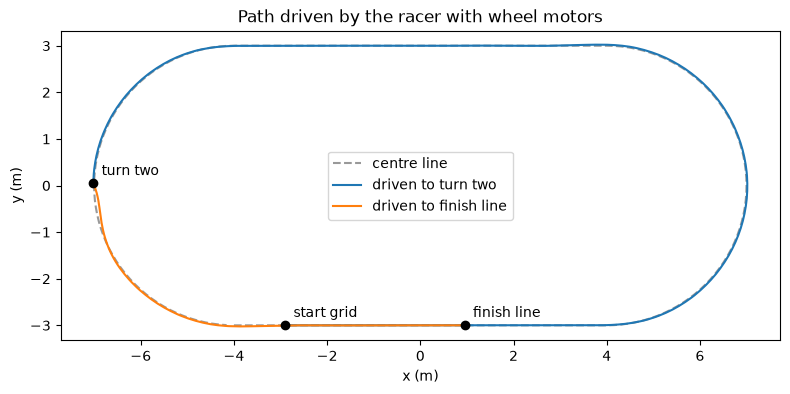

In [13]:
for label, (pos, yaw) in ROBOT_POSES.items():
    goal = POSE_TARGETS[label]
    err = np.linalg.norm(pos[:2] - np.asarray(goal))
    head_err = abs((yaw - heading_of_path(goal) + math.pi) % (2 * math.pi) - math.pi)
    _, orn = p.getBasePositionAndOrientation(robot)
    assert err < 0.15, f"{label}: position error {err:.3f} m"
    assert math.degrees(head_err) < 15, f"{label}: heading error {math.degrees(head_err):.1f} deg"
    assert abs(pos[2] - ROBOT_Z) < 0.03, f"{label}: robot height {pos[2]:.3f} m, it may have tipped"
print("The wheel motor drive reached all three poses.")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(PATH[:, 0], PATH[:, 1], "--", color="0.6", label="centre line")
colors = {"turn two": "tab:blue", "finish line": "tab:orange"}
for label, log in DRIVE_LOGS.items():
    ax.plot(log[:, 1], log[:, 2], color=colors[label], label=f"driven to {label}")
for label, (pos, yaw) in ROBOT_POSES.items():
    ax.plot(pos[0], pos[1], "ko")
    ax.annotate(label, (pos[0], pos[1]), textcoords="offset points", xytext=(6, 6))
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Path driven by the racer with wheel motors")
ax.legend(loc="center")
fig.tight_layout()
fig.savefig(FIG_DIR / "driven_path.png", dpi=120)
plt.show()

## 6. Three cameras, three robot poses

The cameras never move. The robot moves between captures. Each capture renders all three views,
so the notebook makes nine images. To reproduce a pose for rendering, the notebook puts the
robot back at the pose it reached by driving (`resetBasePositionAndOrientation` with the logged pose).

In [14]:
WIDTH, HEIGHT = 640, 480
CAMERAS = {
    # The tiny renderer draws a false shadow band from straight above, so shadows are off there.
    "top-down overview": dict(eye=(0.0, -1.5, 23.0), target=(0.0, -1.5, 0.0), up=(0, 1, 0), fov=55, shadow=0),
    "grandstand side": dict(eye=(0.5, -11.5, 5.5), target=(0.0, 0.5, 0.0), up=(0, 0, 1), fov=60, shadow=1),
    "low corner": dict(eye=(-10.0, -7.0, 1.5), target=(-4.0, -1.5, 0.0), up=(0, 0, 1), fov=45, shadow=1),
}


def render(cam):
    view = p.computeViewMatrix(cam["eye"], cam["target"], cam["up"])
    proj = p.computeProjectionMatrixFOV(cam["fov"], WIDTH / HEIGHT, 0.1, 60.0)
    _, _, rgb, depth, seg = p.getCameraImage(
        WIDTH, HEIGHT, view, proj,
        renderer=p.ER_TINY_RENDERER, shadow=cam["shadow"], lightDirection=(-3, -4, 8),
    )
    rgb = np.reshape(rgb, (HEIGHT, WIDTH, 4))[:, :, :3].astype(np.uint8)
    seg = np.reshape(seg, (HEIGHT, WIDTH)).astype(np.int64)
    return rgb, seg


def place_robot(label):
    pos, yaw = ROBOT_POSES[label]
    p.resetBasePositionAndOrientation(robot, pos.tolist(), p.getQuaternionFromEuler((0, 0, yaw)))


CAPTURES = {}
for label in ROBOT_POSES:
    place_robot(label)
    CAPTURES[label] = {
        "static": snapshot_static(),
        "images": {cam: render(cfg) for cam, cfg in CAMERAS.items()},
    }
    print(f"Captured {label}")

Captured start grid


Captured turn two


Captured finish line


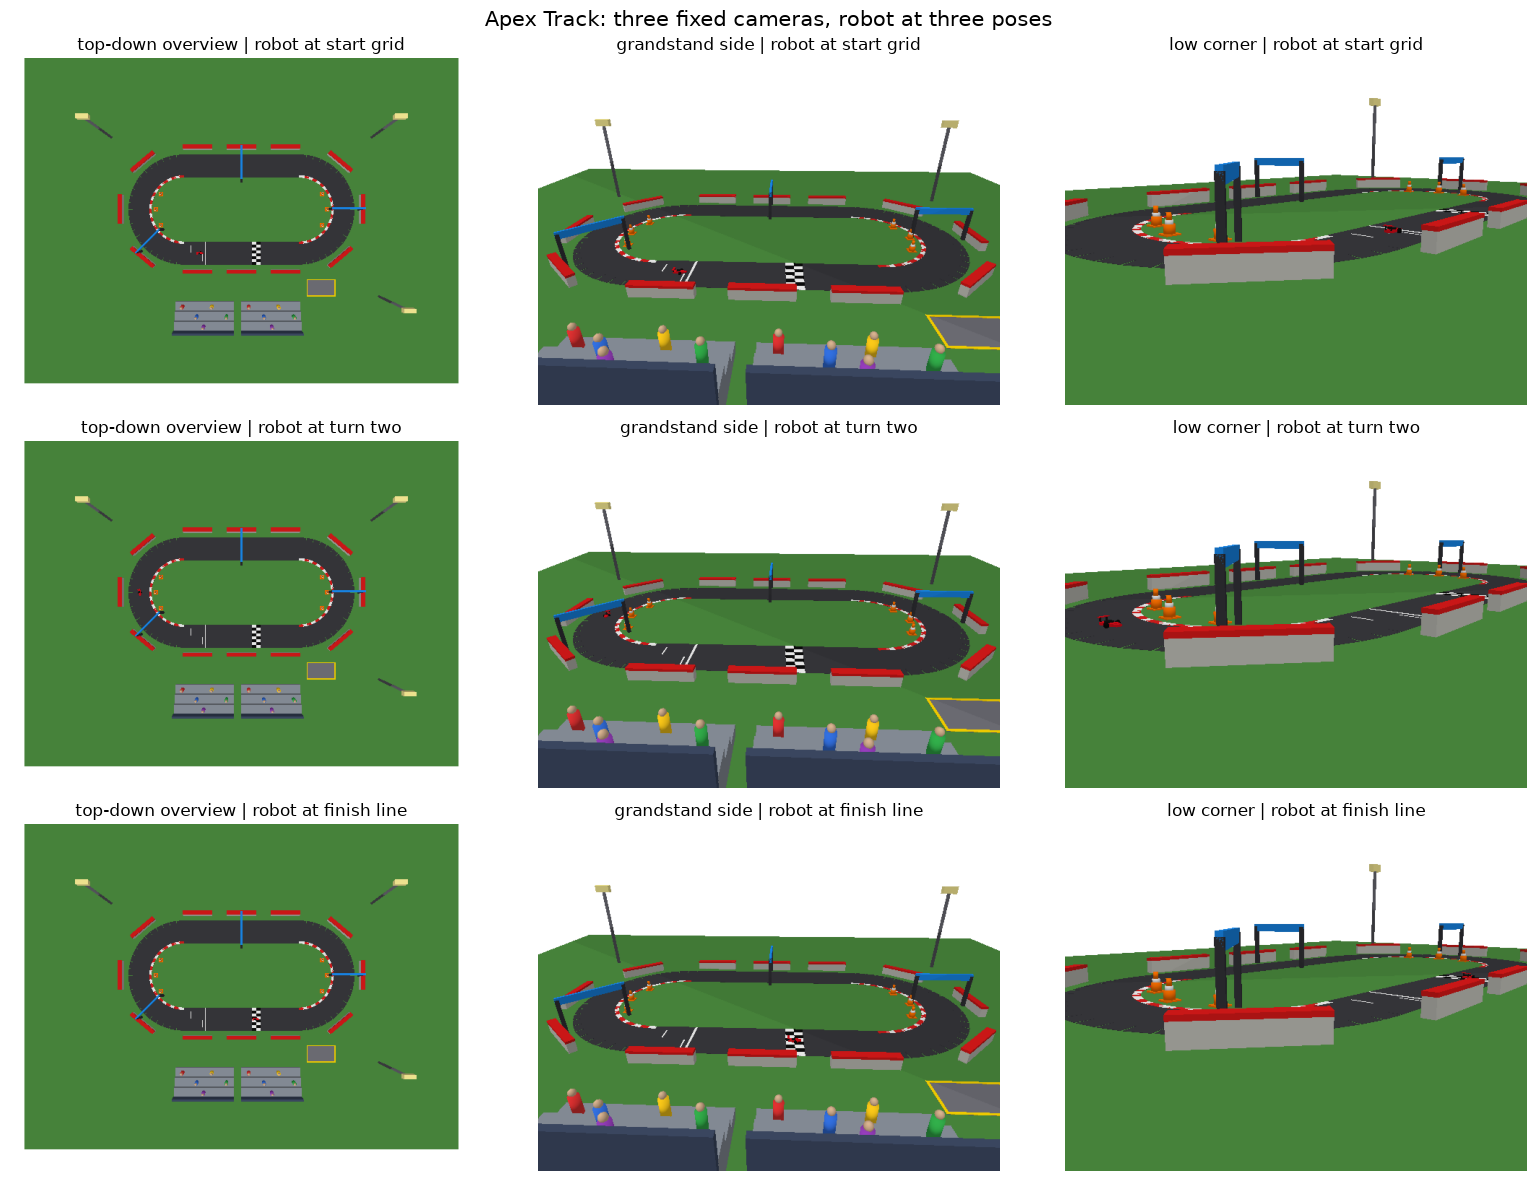

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for r, (label, cap) in enumerate(CAPTURES.items()):
    for c, (cam, (rgb, seg)) in enumerate(cap["images"].items()):
        ax = axes[r, c]
        ax.imshow(rgb)
        ax.set_title(f"{cam} | robot at {label}")
        ax.axis("off")
fig.suptitle("Apex Track: three fixed cameras, robot at three poses", fontsize=15)
fig.tight_layout()
fig.savefig(FIG_DIR / "camera_grid.png", dpi=100)
plt.show()

## 7. Checks with assert

1. Static object poses match across all three captures.
2. The robot appears in all three captures, and in every view. The segmentation mask holds the
   body id of each pixel, so the check counts pixels equal to the robot id.
3. Every body id appears in at least one image.

In [16]:
labels = list(CAPTURES)
ref = CAPTURES[labels[0]]["static"]
for label in labels[1:]:
    snap = CAPTURES[label]["static"]
    assert snap.keys() == ref.keys()
    for b in ref:
        assert np.allclose(ref[b][0], snap[b][0], atol=1e-9), f"{describe(b)} moved in {label}"
        assert np.allclose(ref[b][1], snap[b][1], atol=1e-9), f"{describe(b)} turned in {label}"
print(f"Check 1 passed: {len(ref)} static bodies have the same pose in all {len(labels)} captures.")

# The poses at render time must also match the poses logged during the drive.
for label in labels:
    for b, (pos, orn) in STATIC_SNAPSHOTS[label].items():
        assert np.allclose(pos, CAPTURES[label]["static"][b][0], atol=1e-9)

print("\nRobot pixels per image:")
for label, cap in CAPTURES.items():
    for cam, (rgb, seg) in cap["images"].items():
        n = int(np.sum(seg == robot))
        print(f"  {label:12s} | {cam:18s}: {n:5d} pixels")
        assert n > 0, f"robot not visible in {cam} at {label}"
print("Check 2 passed: the robot is visible in all nine images.")

seen = set()
for cap in CAPTURES.values():
    for rgb, seg in cap["images"].values():
        ids = np.unique(seg)
        seen |= {int(i) & ((1 << 24) - 1) for i in ids if i >= 0}
missing = [describe(b) for b in REGISTRY if b not in seen]
assert not missing, f"bodies never seen: {missing}"
print(f"Check 3 passed: all {len(REGISTRY)} bodies appear in at least one image.")

Check 1 passed: 40 static bodies have the same pose in all 3 captures.

Robot pixels per image:
  start grid   | top-down overview :    34 pixels
  start grid   | grandstand side   :   124 pixels
  start grid   | low corner        :   210 pixels
  turn two     | top-down overview :    37 pixels
  turn two     | grandstand side   :    64 pixels
  turn two     | low corner        :   333 pixels
  finish line  | top-down overview :    29 pixels
  finish line  | grandstand side   :   120 pixels
  finish line  | low corner        :    98 pixels
Check 2 passed: the robot is visible in all nine images.
Check 3 passed: all 41 bodies appear in at least one image.


The segmentation masks themselves, for the first capture. Each colour is one body id.

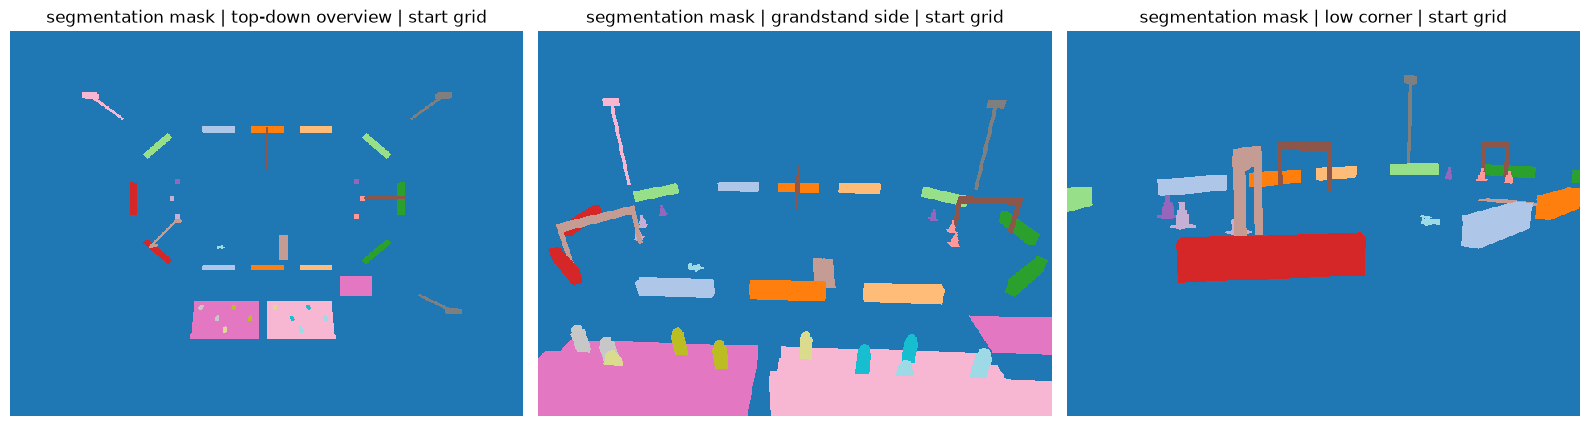

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (cam, (rgb, seg)) in zip(axes, CAPTURES["start grid"]["images"].items()):
    ax.imshow(seg, cmap="tab20", interpolation="nearest")
    ax.set_title(f"segmentation mask | {cam} | start grid")
    ax.axis("off")
fig.tight_layout()
plt.show()

Close ups of the robot. Each crop is cut around the robot pixels in the segmentation mask, so it
also shows that the code finds the robot by its body id.

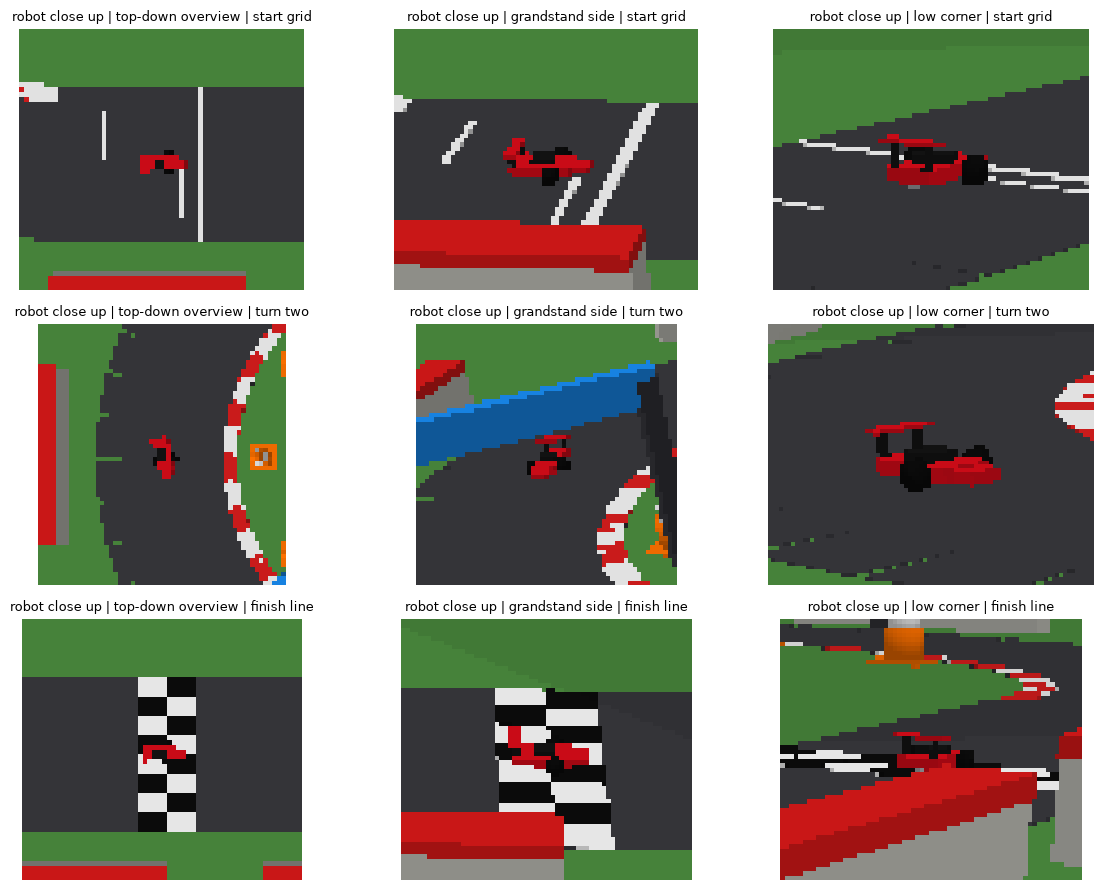

In [18]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for r, (label, cap) in enumerate(CAPTURES.items()):
    for c, (cam, (rgb, seg)) in enumerate(cap["images"].items()):
        rows, cols = np.nonzero(seg == robot)
        pad = 25
        r0, r1 = max(rows.min() - pad, 0), min(rows.max() + pad, HEIGHT)
        c0, c1 = max(cols.min() - pad, 0), min(cols.max() + pad, WIDTH)
        ax = axes[r, c]
        ax.imshow(rgb[r0:r1, c0:c1], interpolation="nearest")
        ax.set_title(f"robot close up | {cam} | {label}", fontsize=9)
        ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "robot_closeups.png", dpi=100)
plt.show()

## 8. Interaction: three queries

### 8.1 Highlight one role

Recolour every obstacle bright magenta, render the top-down view, then restore the colours.

Highlighted 18 obstacles. Pixels changed: 3875. Pixels different after restore: 0.


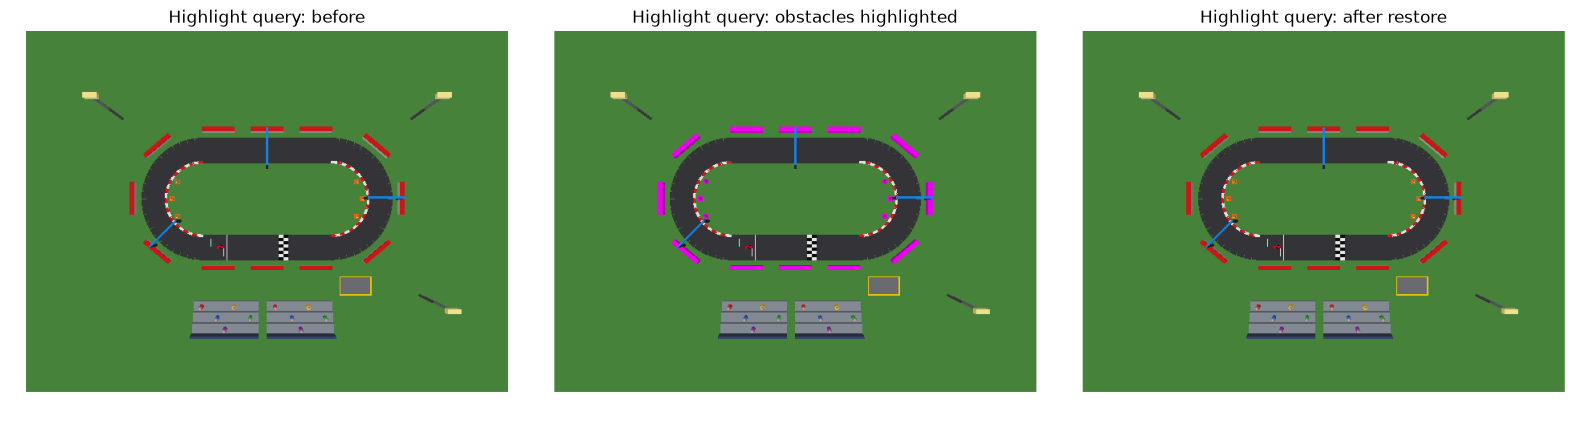

In [19]:
def visual_colours(body_id):
    """Original colour of every visual shape, keyed by link, in the order PyBullet stores them."""
    out = {}
    for shape_data in p.getVisualShapeData(body_id):
        out.setdefault(shape_data[1], []).append(shape_data[7])
    return out


def highlight(role, colour=(1.0, 0.0, 1.0, 1.0)):
    saved = {}
    for b in objects_by_role(role):
        saved[b] = visual_colours(b)
        for link in saved[b]:
            p.changeVisualShape(b, link, rgbaColor=colour)
    return saved


def restore(saved):
    for b, links in saved.items():
        for link, colours in links.items():
            for i, c in enumerate(colours):
                p.changeVisualShape(b, link, shapeIndex=i, rgbaColor=c)


place_robot("start grid")
before, _ = render(CAMERAS["top-down overview"])
saved = highlight("obstacle")
during, _ = render(CAMERAS["top-down overview"])
restore(saved)
after, _ = render(CAMERAS["top-down overview"])

changed = int(np.any(before != during, axis=2).sum())
restored = int(np.any(before != after, axis=2).sum())
print(f"Highlighted {len(saved)} obstacles. Pixels changed: {changed}. Pixels different after restore: {restored}.")
assert changed > 0 and restored == 0

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, img, title in zip(axes, (before, during, after),
                          ("before", "obstacles highlighted", "after restore")):
    ax.imshow(img)
    ax.set_title(f"Highlight query: {title}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "highlight_obstacles.png", dpi=100)
plt.show()

### 8.2 Nearest object to the robot at each pose

PyBullet's `getClosestPoints` measures the gap between surfaces, so this is clearance, not
centre to centre distance. Ground and track are skipped.

In [20]:
for label in ROBOT_POSES:
    place_robot(label)
    p.performCollisionDetection()
    b, d = nearest_object(robot)
    e = REGISTRY[b]
    gap = "touching it" if d < 0.01 else f"{d:.2f} m away"
    print(f"At {label:12s} the nearest object is {e['name']} (role: {e['role']}), {gap}.")

At start grid   the nearest object is barrier front straight 1 (role: obstacle), 0.99 m away.
At turn two     the nearest object is apex cone turn two 2 (role: obstacle), 0.81 m away.
At finish line  the nearest object is finish line (role: target zone), touching it.


### 8.3 Role lookup by position

Give an x, y point. The query prints what stands there, from the registry.

In [21]:
place_robot("finish line")
QUERY_POINTS = [(FINISH_X, -TRACK_RADIUS), (5.5, -5.4), (-2.5, -7.2), (0.0, TRACK_RADIUS), (0.0, 0.0)]
for x, y in QUERY_POINTS:
    hits = zone_at(x, y)
    if not hits:
        print(f"({x:5.2f}, {y:5.2f}): open ground, nothing stands here")
        continue
    names = "; ".join(f"{REGISTRY[b]['name']} (role: {REGISTRY[b]['role']})" for b in hits)
    print(f"({x:5.2f}, {y:5.2f}): {names}")

( 1.00, -3.00): Apex racer (role: robot); finish line (role: target zone)
( 5.50, -5.40): pit box (role: zone)
(-2.50, -7.20): main grandstand west (role: landmark)
( 0.00,  3.00): checkpoint 2 (back straight) (role: target)
( 0.00,  0.00): open ground, nothing stands here


## 9. Reflection (DRAFT)

**DRAFT. Rewrite this section in your own words before you submit.** It is built from the
entries in docs/attempts.md.

**What worked.** The racer reached all three poses by driving on its own wheel motors. Pure pursuit
on the centre line brought it within 5 cm of each target and within 11 degrees of the track
heading. So the notebook did not need the `resetBasePositionAndOrientation` fallback to get there.
It only uses that call to put the car back at a logged pose before each render. The registry made
the queries short. Each one is a loop over a dict keyed by body id.

**Failed attempts.**

1. *Long URDF lines.* The first track URDF was one long line of XML. PyBullet refused it with
   `XML_ERROR_PARSING_ATTRIBUTE`, while Python's XML parser read the same file. Writing one tag per
   line fixed it.
2. *Gate posts on the racing line.* The first gate yaws put the posts across the car's path. The
   car drove into a post in turn one and stopped 13.8 m short of its goal. Setting each gate's yaw
   to the track heading moved the posts outside the track.
3. *Blocked corner camera.* A light tower filled the middle of the low corner view. The barriers
   hid the car at the finish line, where the mask held only 2 robot pixels. Moving the tower and
   raising the camera to 1.5 m fixed both.
4. *False shadow band.* The tiny renderer drew a dark diagonal band in the top-down view. It moved
   with the light direction, so it was a shadow map artifact. Shadows are now off for that camera.

**What I would change.** The segmentation mask asserts caught the hidden robot before I looked at
the images. Next time I would write those checks first. The robot is small in the wide views, so
the close ups cut from the mask carry most of the detail.

In [22]:
p.disconnect()
print("Disconnected.")

Disconnected.
